# Infra：理论预算与真实计时

无需模型权重。前半验证 TP、ZeRO 和 matmul（CUDA 可用时 matmul 会选择 GPU）；第 5–9 节固定 CPU FP32，逐步实现两层 Decoder 的 KV cache，检查 FP32/FP64 正确性、错误对照和续算计时。GPU/TPU 与框架性能不在该 KV 实验的结论范围内。

执行状态：编写时已在 CPU 上运行，下方为真实输出；CUDA/TPU 路径未经测试。请重新运行以获取你的环境结果。

In [1]:
import sys, subprocess, importlib.util
requirements = {'torch': 'torch>=2.6,<3', 'numpy': 'numpy', 'matplotlib': 'matplotlib'}
missing = [package for module, package in requirements.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
import torch, numpy as np, matplotlib.pyplot as plt
print({'python': sys.version.split()[0], 'torch': torch.__version__, 'numpy': np.__version__, 'cuda': torch.cuda.is_available()})
torch.manual_seed(7); np.random.seed(7)
torch.set_num_threads(min(4, torch.get_num_threads()))


{'python': '3.12.14', 'torch': '2.15.0+cpu', 'numpy': '2.3.5', 'cuda': False}


## 1 · 显存账本
改并发和长度。GiB 用 2³⁰，GB 用 10⁹；两者不要混用。

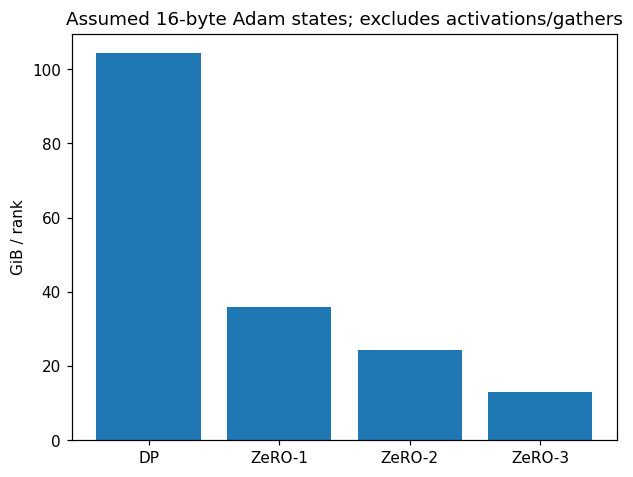

KV GiB: 2.0
ZeRO 0: 104.308 GiB per rank (persistent state only)
ZeRO 1: 35.856 GiB per rank (persistent state only)
ZeRO 2: 24.447 GiB per rank (persistent state only)
ZeRO 3: 13.039 GiB per rank (persistent state only)


In [2]:
B,T,L,Hkv,Dh,bytes_per_element=4,4096,32,8,128,2
kv=2*B*T*L*Hkv*Dh*bytes_per_element
print('KV GiB:',kv/2**30)
assert kv/2**30 == 2
N,P=7_000_000_000,8
states=[16*N,4*N+12*N/P,2*N+14*N/P,16*N/P]
for stage,bytes_used in enumerate(states):
    print(f'ZeRO {stage}: {bytes_used/2**30:.3f} GiB per rank (persistent state only)')
plt.bar(['DP','ZeRO-1','ZeRO-2','ZeRO-3'],np.array(states)/2**30)
plt.ylabel('GiB / rank');plt.title('Assumed 16-byte Adam states; excludes activations/gathers');plt.show()


## 2 · 模拟张量并行，验证数值
这是单进程模拟，没有 NCCL 通信，不能测 scaling。

In [3]:
x,w=torch.randn(16,64),torch.randn(64,128)
ref=x@w
column=torch.cat([x@part for part in w.chunk(4,dim=1)],dim=1)
row=sum(a@b for a,b in zip(x.chunk(4,dim=1),w.chunk(4,dim=0)))
assert torch.allclose(column,ref,atol=1e-4,rtol=1e-4)
assert torch.allclose(row,ref,atol=1e-4,rtol=1e-4)
print('Column and row partition equivalence passed.')
S=64*1024**2
print('Ideal ring all-reduce MiB/rank:',2*(P-1)/P*S/2**20)


Column and row partition equivalence passed.
Ideal ring all-reduce MiB/rank: 112.0


## 3 · 真实 matmul 时间
先 warm-up，GPU 用 events，CPU 用 perf_counter。输出包含所有 repeats 的分布；没有外推成服务吞吐。

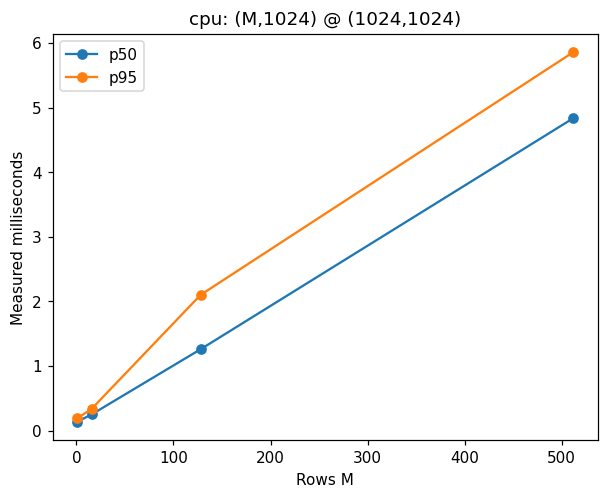

device: x86_64
dtype: torch.float32
{'m': 1, 'p50_ms': 0.13689600001498547, 'p95_ms': 0.18826890006948824}
{'m': 16, 'p50_ms': 0.25251499999967564, 'p95_ms': 0.34028234993570555}
{'m': 128, 'p50_ms': 1.258870000015122, 'p95_ms': 2.1000210499039444}
{'m': 512, 'p50_ms': 4.83518050003795, 'p95_ms': 5.8574007000117945}


In [4]:
import time, platform
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
DTYPE=torch.float16 if DEVICE=='cuda' else torch.float32
print('device:',torch.cuda.get_device_name(0) if DEVICE=='cuda' else platform.processor() or 'CPU')
print('dtype:',DTYPE)
results=[]
for m in [1,16,128,512]:
    a=torch.randn(m,1024,device=DEVICE,dtype=DTYPE)
    b=torch.randn(1024,1024,device=DEVICE,dtype=DTYPE)
    for _ in range(8): c=a@b
    times=[]
    for _ in range(20):
        if DEVICE=='cuda':
            start,end=torch.cuda.Event(enable_timing=True),torch.cuda.Event(enable_timing=True)
            start.record(); c=a@b; end.record(); end.synchronize()
            elapsed=start.elapsed_time(end)
        else:
            start=time.perf_counter(); c=a@b; elapsed=(time.perf_counter()-start)*1000
        times.append(elapsed)
    row={'m':m,'p50_ms':float(np.median(times)),'p95_ms':float(np.percentile(times,95))}
    results.append(row);print(row)
    assert torch.isfinite(c).all()
plt.plot([r['m'] for r in results],[r['p50_ms'] for r in results],marker='o',label='p50')
plt.plot([r['m'] for r in results],[r['p95_ms'] for r in results],marker='o',label='p95')
plt.xlabel('Rows M');plt.ylabel('Measured milliseconds');plt.title(f'{DEVICE}: (M,1024) @ (1024,1024)');plt.legend();plt.show()


## 4 · 保存可复查的结果
这个 JSON 包含环境与实测值，不含未执行的 GPU 数字。下一步可固定一个 shape，用 Nsight/XProf 分析对应实现。

In [5]:
import json
report={'device':DEVICE,'dtype':str(DTYPE),'torch':torch.__version__,'threads':torch.get_num_threads(),'results':results}
with open('infra-benchmark-results.json','w') as f: json.dump(report,f,indent=2)
print(json.dumps(report,indent=2))


{
  "device": "cpu",
  "dtype": "torch.float32",
  "torch": "2.15.0+cpu",
  "threads": 4,
  "results": [
    {
      "m": 1,
      "p50_ms": 0.13689600001498547,
      "p95_ms": 0.18826890006948824
    },
    {
      "m": 16,
      "p50_ms": 0.25251499999967564,
      "p95_ms": 0.34028234993570555
    },
    {
      "m": 128,
      "p50_ms": 1.258870000015122,
      "p95_ms": 2.1000210499039444
    },
    {
      "m": 512,
      "p50_ms": 4.83518050003795,
      "p95_ms": 5.8574007000117945
    }
  ]
}


## 5 · 从零实现两层 Decoder
固定 seed、CPU FP32、两层 pre-norm、4 个 MHA heads、learned positions，无 dropout。模型未训练，只检验计算一致性。每层独立缓存投影后的 K/V；动态拼接保持旧 cache 不变。

In [6]:
import math
import torch.nn as nn
import torch.nn.functional as F
torch.manual_seed(42)
torch.set_num_threads(1)

class CacheBlock(nn.Module):
    def __init__(self, width=64, heads=4):
        super().__init__()
        self.heads, self.head_dim = heads, width // heads
        assert width % heads == 0
        self.ln1, self.ln2 = nn.LayerNorm(width), nn.LayerNorm(width)
        self.qkv, self.out = nn.Linear(width, 3*width), nn.Linear(width, width)
        self.ff = nn.Sequential(nn.Linear(width, 4*width), nn.GELU(), nn.Linear(4*width, width))

    def forward(self, x, past=None, offset_mask=True):
        b, n, d = x.shape
        q, k, v = self.qkv(self.ln1(x)).chunk(3, dim=-1)
        q, k, v = [t.reshape(b, n, self.heads, self.head_dim).transpose(1, 2) for t in (q, k, v)]
        past_len = 0 if past is None else past[0].shape[-2]
        if past is not None:
            k = torch.cat((past[0], k), dim=-2)
            v = torch.cat((past[1], v), dim=-2)
        # Local query i corresponds to absolute position past_len + i.
        query_pos = torch.arange(n) + (past_len if offset_mask else 0)
        key_pos = torch.arange(k.shape[-2])
        allowed = key_pos[None, :] <= query_pos[:, None]
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        weights = scores.masked_fill(~allowed, -torch.inf).softmax(dim=-1)
        context = (weights @ v).transpose(1, 2).reshape(b, n, d)
        x = x + self.out(context)
        x = x + self.ff(self.ln2(x))
        return x, (k, v)

class CacheDecoder(nn.Module):
    def __init__(self, vocab=97, width=64, heads=4, layers=2, max_positions=512):
        super().__init__()
        self.token = nn.Embedding(vocab, width)
        self.position = nn.Embedding(max_positions, width)
        self.blocks = nn.ModuleList([CacheBlock(width, heads) for _ in range(layers)])
        self.norm, self.head = nn.LayerNorm(width), nn.Linear(width, vocab, bias=False)

    def forward(self, ids, cache=None, use_cache=True, reset_positions=False, offset_mask=True):
        past_len = 0 if cache is None else cache[0][0].shape[-2]
        if cache is not None:
            assert len(cache) == len(self.blocks)
            assert all(k.shape[-2] == past_len == v.shape[-2] for k, v in cache)
        start = 0 if reset_positions else past_len
        positions = torch.arange(start, start + ids.shape[1])
        x = self.token(ids) + self.position(positions)[None, :, :]
        updated = []
        for layer, block in enumerate(self.blocks):
            x, kv = block(x, None if cache is None else cache[layer], offset_mask=offset_mask)
            if use_cache:
                updated.append(kv)
        return self.head(self.norm(x)), tuple(updated)

decoder = CacheDecoder().cpu().float().eval()
fixed_ids = torch.randint(0, 97, (2, 288))
print('parameters:', sum(p.numel() for p in decoder.parameters()))
with torch.inference_mode():
    prefill_logits, prefix_cache = decoder(fixed_ids[:, :5])
print('prefill logits:', tuple(prefill_logits.shape))
print('per-layer K/V:', [(tuple(k.shape), tuple(v.shape)) for k, v in prefix_cache])


parameters: 145280
prefill logits: (2, 5, 97)
per-layer K/V: [((2, 4, 5, 16), (2, 4, 5, 16)), ((2, 4, 5, 16), (2, 4, 5, 16))]


## 6 · 逐位置比较 logits 与每层 K/V
对 batch=1/2、chunk=1/2/5 和 FP32/FP64 分别检查全部 24 个位置。断言检查全部词表 logits，而不是只比较 argmax；同时检查因果性、cache 长度和旧 cache 未被原地修改。

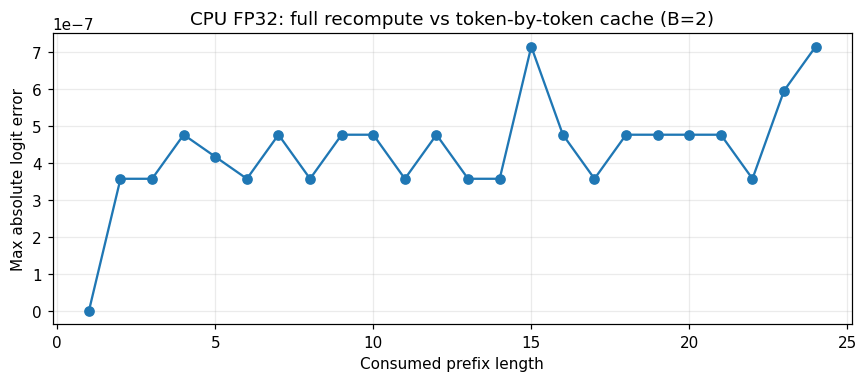

{'dtype': 'torch.float32', 'batch': 1, 'chunk': 1, 'max_abs_logit_error': 8.344650268554688e-07}
{'dtype': 'torch.float32', 'batch': 1, 'chunk': 2, 'max_abs_logit_error': 5.960464477539062e-07}
{'dtype': 'torch.float32', 'batch': 1, 'chunk': 5, 'max_abs_logit_error': 4.76837158203125e-07}
{'dtype': 'torch.float32', 'batch': 2, 'chunk': 1, 'max_abs_logit_error': 7.152557373046875e-07}
{'dtype': 'torch.float32', 'batch': 2, 'chunk': 2, 'max_abs_logit_error': 4.76837158203125e-07}
{'dtype': 'torch.float32', 'batch': 2, 'chunk': 5, 'max_abs_logit_error': 4.76837158203125e-07}
{'dtype': 'torch.float64', 'batch': 1, 'chunk': 1, 'max_abs_logit_error': 1.1102230246251565e-15}
{'dtype': 'torch.float64', 'batch': 1, 'chunk': 2, 'max_abs_logit_error': 1.1102230246251565e-15}
{'dtype': 'torch.float64', 'batch': 1, 'chunk': 5, 'max_abs_logit_error': 1.5543122344752192e-15}
{'dtype': 'torch.float64', 'batch': 2, 'chunk': 1, 'max_abs_logit_error': 1.1102230246251565e-15}
{'dtype': 'torch.float64', 'b

In [7]:
from copy import deepcopy
correctness = []
with torch.inference_mode():
    for dtype, atol in [(torch.float32, 1e-5), (torch.float64, 1e-10)]:
        checked = deepcopy(decoder).to(dtype=dtype)
        for batch in [1, 2]:
            tokens = fixed_ids[:batch, :24]
            full, full_cache = checked(tokens)
            changed = tokens.clone()
            changed[:, -1] = (changed[:, -1] + 1) % 97
            alternate, _ = checked(changed, use_cache=False)
            torch.testing.assert_close(full[:, :-1], alternate[:, :-1], atol=atol, rtol=atol)
            for chunk in [1, 2, 5]:
                cache, outputs, errors = None, [], []
                for start in range(0, tokens.shape[1], chunk):
                    end = min(start + chunk, tokens.shape[1])
                    old = None if cache is None else tuple((k.clone(), v.clone()) for k, v in cache)
                    logits, new_cache = checked(tokens[:, start:end], cache)
                    reference, reference_cache = checked(tokens[:, :end])
                    torch.testing.assert_close(logits, reference[:, start:end], atol=atol, rtol=atol)
                    for layer, (k, v) in enumerate(new_cache):
                        assert k.shape == v.shape == (batch, 4, end, 16)
                        for value, target in zip((k, v), reference_cache[layer]):
                            torch.testing.assert_close(value, target, atol=atol, rtol=atol)
                        if old is not None:
                            assert torch.equal(cache[layer][0], old[layer][0])
                            assert torch.equal(cache[layer][1], old[layer][1])
                    outputs.append(logits)
                    errors.extend((logits-reference[:, start:end]).abs().amax(dim=(0, 2)).tolist())
                    cache = new_cache
                torch.testing.assert_close(torch.cat(outputs, dim=1), full, atol=atol, rtol=atol)
                row = {'dtype': str(dtype), 'batch': batch, 'chunk': chunk, 'max_abs_logit_error': max(errors)}
                correctness.append(row)
                print(row)
                if dtype == torch.float32 and batch == 2 and chunk == 1:
                    position_errors = errors
plt.figure(figsize=(8, 3.6))
plt.plot(range(1, 25), position_errors, marker='o')
plt.xlabel('Consumed prefix length'); plt.ylabel('Max absolute logit error')
plt.title('CPU FP32: full recompute vs token-by-token cache (B=2)')
plt.grid(alpha=.25); plt.tight_layout(); plt.show()


## 7 · 故意写错位置与 mask
cache 长度为 4，当前 chunk 为 2：query 的绝对位置是 4、5。将位置重置为 0，或使用左上角三角 mask，都会改变输出；反例必须明显偏离正确参考。

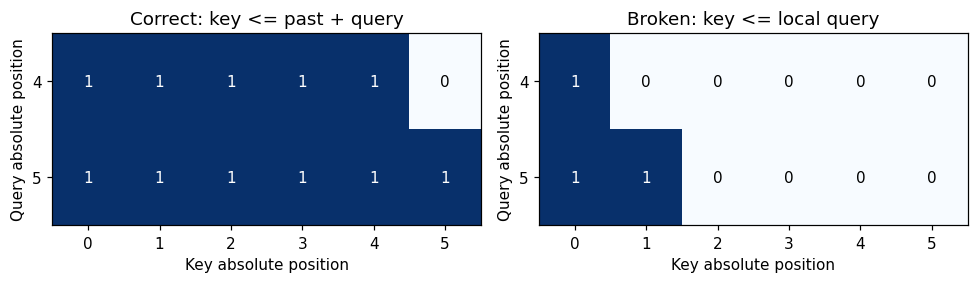

reset_positions max absolute logit error: 1.8941389322280884
unshifted_mask max absolute logit error: 0.3938286304473877


In [8]:
with torch.inference_mode():
    tokens = fixed_ids[:1, :6]
    reference, _ = decoder(tokens, use_cache=False)
    _, cache = decoder(tokens[:, :4])
    negative_controls = {}
    for name, options in [('reset_positions', {'reset_positions': True}), ('unshifted_mask', {'offset_mask': False})]:
        wrong, _ = decoder(tokens[:, 4:], cache, **options)
        error = (wrong-reference[:, 4:]).abs().max().item()
        assert error > 1e-3
        negative_controls[name] = error
        print(name, 'max absolute logit error:', error)
past_len, new_len = 4, 2
keys = torch.arange(past_len + new_len)
correct_mask = keys[None, :] <= (past_len + torch.arange(new_len))[:, None]
wrong_mask = keys[None, :] <= torch.arange(new_len)[:, None]
fig, axes = plt.subplots(1, 2, figsize=(9, 2.7))
for ax, mask, title in zip(axes, [correct_mask, wrong_mask], ['Correct: key <= past + query', 'Broken: key <= local query']):
    ax.imshow(mask.numpy(), cmap='Blues', vmin=0, vmax=1, aspect='auto')
    ax.set(xticks=range(6), yticks=range(2), yticklabels=[4, 5], xlabel='Key absolute position', ylabel='Query absolute position', title=title)
    for i in range(2):
        for j in range(6):
            ax.text(j, i, int(mask[i, j]), ha='center', va='center', color='white' if mask[i, j] else 'black')
plt.tight_layout(); plt.show()


## 8 · 固定 token 流，分开 prefill 与续算计时
CPU FP32、单线程；每种路径预热 3 次、重复 15 次，交替测量完整重算和缓存。Decode 窗口都消费相同的 16 个预定 token，输出每步全部 logits；prefix prefill 单独计时，cache 创建后复用且不原地修改。动态 cat、分配和 Python 开销包含在内。此窗口不是客户端 TTFT/ITL。

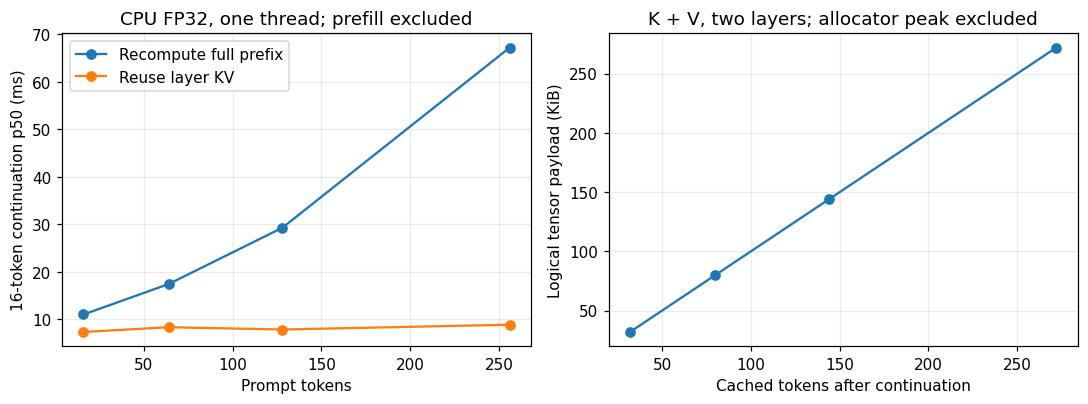

{'prompt_tokens': 16, 'appended_tokens': 16, 'cache_payload_bytes': 32768, 'full_projected_positions_per_layer': 392, 'cached_projected_positions_per_layer': 16, 'prefill_p50_ms': 0.565539, 'prefill_p95_ms': 0.8771151999999995, 'full_p50_ms': 10.998736, 'full_p95_ms': 11.4971841, 'cached_p50_ms': 7.314643, 'cached_p95_ms': 9.2133261}
{'prompt_tokens': 64, 'appended_tokens': 16, 'cache_payload_bytes': 81920, 'full_projected_positions_per_layer': 1160, 'cached_projected_positions_per_layer': 16, 'prefill_p50_ms': 1.009386, 'prefill_p95_ms': 1.0875625, 'full_p50_ms': 17.421139, 'full_p95_ms': 18.7295622, 'cached_p50_ms': 8.319462, 'cached_p95_ms': 9.4834888}
{'prompt_tokens': 128, 'appended_tokens': 16, 'cache_payload_bytes': 147456, 'full_projected_positions_per_layer': 2184, 'cached_projected_positions_per_layer': 16, 'prefill_p50_ms': 1.703033, 'prefill_p95_ms': 1.9419273, 'full_p50_ms': 29.273538, 'full_p95_ms': 50.73695949999998, 'cached_p50_ms': 7.831908, 'cached_p95_ms': 9.2627478}

In [9]:
import time, platform, os
NEW_TOKENS, REPEATS, WARMUPS = 16, 15, 3
kv_timings = []

def timed_ms(fn):
    start = time.perf_counter_ns()
    fn()
    return (time.perf_counter_ns() - start) / 1e6

with torch.inference_mode():
    for prompt in [16, 64, 128, 256]:
        stream = fixed_ids[:1, :prompt + NEW_TOKENS]
        _, seed_cache = decoder(stream[:, :prompt])

        def prefill():
            return decoder(stream[:, :prompt])

        def full_continuation():
            rows = []
            for j in range(NEW_TOKENS):
                logits, _ = decoder(stream[:, :prompt+j+1], use_cache=False)
                rows.append(logits[:, -1:])
            return torch.cat(rows, dim=1)

        def cached_continuation():
            cache, rows = seed_cache, []
            for j in range(NEW_TOKENS):
                logits, cache = decoder(stream[:, prompt+j:prompt+j+1], cache)
                rows.append(logits)
            return torch.cat(rows, dim=1), cache

        cached_logits, final_cache = cached_continuation()
        torch.testing.assert_close(cached_logits, full_continuation(), atol=1e-5, rtol=1e-5)
        for _ in range(WARMUPS):
            prefill(); full_continuation(); cached_continuation()
        samples = {'prefill': [], 'full': [], 'cached': []}
        functions = {'prefill': prefill, 'full': full_continuation, 'cached': cached_continuation}
        for repeat in range(REPEATS):
            # Rotate all three paths so no path is always measured first.
            order = ['prefill', 'full', 'cached']
            order = order[repeat % 3:] + order[:repeat % 3]
            for path in order:
                samples[path].append(timed_ms(functions[path]))
        actual_bytes = sum(t.numel()*t.element_size() for pair in final_cache for t in pair)
        expected_bytes = 2 * 1 * (prompt+NEW_TOKENS) * 2 * 4 * 16 * 4
        assert actual_bytes == expected_bytes
        row = {'prompt_tokens': prompt, 'appended_tokens': NEW_TOKENS, 'cache_payload_bytes': actual_bytes,
               'samples_ms': samples, 'full_projected_positions_per_layer': sum(prompt+j+1 for j in range(NEW_TOKENS)),
               'cached_projected_positions_per_layer': NEW_TOKENS}
        for path in samples:
            row[path+'_p50_ms'] = float(np.median(samples[path]))
            row[path+'_p95_ms'] = float(np.percentile(samples[path], 95))
        kv_timings.append(row)
        print({k: v for k, v in row.items() if k != 'samples_ms'})
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for path, label in [('full', 'Recompute full prefix'), ('cached', 'Reuse layer KV')]:
    axes[0].plot([r['prompt_tokens'] for r in kv_timings], [r[path+'_p50_ms'] for r in kv_timings], marker='o', label=label)
axes[0].set(xlabel='Prompt tokens', ylabel='16-token continuation p50 (ms)', title='CPU FP32, one thread; prefill excluded')
axes[0].legend(); axes[0].grid(alpha=.25)
axes[1].plot([r['prompt_tokens']+NEW_TOKENS for r in kv_timings], [r['cache_payload_bytes']/1024 for r in kv_timings], marker='o')
axes[1].set(xlabel='Cached tokens after continuation', ylabel='Logical tensor payload (KiB)', title='K + V, two layers; allocator peak excluded')
axes[1].grid(alpha=.25); plt.tight_layout(); plt.show()


## 9 · 保存环境、原始样本与正确性结果
结果文件包含全部 15 次样本，p95 是小样本经验分位数。逻辑 tensor 字节数不等于进程峰值或设备峰值。模型未训练、无 padding/GQA/RoPE/采样；这里只验证 MHA 与 learned positions 的缓存机制。

In [10]:
from datetime import datetime, timezone
from pathlib import Path
cpu_name = platform.processor()
if Path('/proc/cpuinfo').is_file():
    cpu_name = next((line.split(':', 1)[1].strip() for line in Path('/proc/cpuinfo').read_text().splitlines() if line.startswith('model name')), cpu_name)
kv_cache_report = {
    'scope': 'Untrained two-layer decoder, synthetic fixed-token continuation; CPU microbenchmark only',
    'environment': {'python': sys.version.split()[0], 'torch': torch.__version__, 'numpy': np.__version__,
                    'device': 'cpu', 'dtype': 'float32', 'threads': torch.get_num_threads(),
                    'platform': platform.platform(), 'cpu': cpu_name, 'logical_cpus': os.cpu_count(),
                    'executed_at_utc': datetime.now(timezone.utc).isoformat(), 'seed': 42},
    'model': {'vocab': 97, 'layers': 2, 'width': 64, 'heads': 4, 'head_dim': 16, 'max_positions': 512,
              'parameters': sum(p.numel() for p in decoder.parameters()), 'trained': False, 'position_encoding': 'learned absolute'},
    'protocol': {'warmups': WARMUPS, 'repeats': REPEATS, 'timer': 'perf_counter_ns',
                 'continuation_prefill_included': False, 'cache': 'immutable dynamic torch.cat',
                 'gradients': 'torch.inference_mode', 'path_order': 'rotated each repeat',
                 'inputs': 'predetermined tokens, no sampling or EOS', 'memory': 'logical final K/V payload only'},
    'correctness': correctness, 'position_errors_fp32_batch2_chunk1': position_errors,
    'negative_controls': negative_controls, 'timings': kv_timings,
}
report['kv_cache'] = kv_cache_report
with open('infra-benchmark-results.json', 'w') as f:
    json.dump(report, f, indent=2)
print(json.dumps(kv_cache_report['environment'], indent=2))
print('Saved raw samples and checks to infra-benchmark-results.json')


{
  "python": "3.12.14",
  "torch": "2.15.0+cpu",
  "numpy": "2.3.5",
  "device": "cpu",
  "dtype": "float32",
  "threads": 1,
  "platform": "Linux-6.18.57-x86_64-with-glibc2.39",
  "cpu": "AMD EPYC 9V74 80-Core Processor",
  "logical_cpus": 9,
  "executed_at_utc": "2026-11-02T14:46:48.920368+00:00",
  "seed": 42
}
Saved raw samples and checks to infra-benchmark-results.json


## 下一步
改变一个参数，先预测结果，再重跑。记录环境、seed、输入与失败情况；不要把教学实验外推成生产结论。